> 📄 **Versión ya ejecutada**, con los resultados y los análisis de Gemini del ejemplo, para leer sin correr nada. Para ejecutarla tú, abre la versión sin resultados: [`taller/pista_C_alphaearth.ipynb`](https://colab.research.google.com/github/alcastaro/codigo-que-salva-vidas/blob/main/taller/pista_C_alphaearth.ipynb).

# 🗺️ Pista C — Tu plataforma de vigilancia satelital con AlphaEarth
**Código que Salva Vidas · DevFest Santo Domingo 2026 · Taller · Nivel principiante**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alcastaro/codigo-que-salva-vidas/blob/main/taller/pista_C_alphaearth.ipynb)

**Amazon Mining Watch** (Earth Genome) vigila con satélite la minería de oro en los nueve países amazónicos: 1,1 millones de hectáreas detectadas hasta 2026.
**Google Earth** estrenó *Classify*: le marcas unos ejemplos y te clasifica cultivos, bosque o barrios usando **AlphaEarth Foundations**.

Aquí construyes tu propia versión para **República Dominicana**, enfocada en **erosión y cambios del suelo**:

| Paso | Pregunta | Cómo |
|---|---|---|
| 1 | ¿Qué hay? | AlphaEarth (64 números por píxel de 10 m) y Sentinel-2 |
| 2 | ¿Dónde cambió entre 2017 y 2025? | Comparar las "huellas" de AlphaEarth de los dos años |
| 3 | ¿Ese cambio está en ladera? | Pendiente del modelo de elevación Copernicus |
| 4 | ¿Qué es cada cosa hoy? | Clasificar con unos pocos ejemplos, como Classify |
| 5 | ¿Cómo se lo explico a alguien? | Informe con Gemini |
| 6 | **Tu plataforma** | Una app web con Gradio y un enlace para compartir |
| 7 | ¿Y en otro lugar? | Adaptar el cuaderno |

Todo con datos abiertos: **no necesitas proyecto de Google Cloud ni de Earth Engine.**
**Importante:** esto da *señales para revisar*, no diagnósticos. Un cambio en ladera puede ser erosión, una cosecha o una obra; hay que verificarlo en terreno.

## ✅ Antes de empezar (3 minutos)

1. **Inicia sesión** en Colab con tu cuenta de Google (arriba a la derecha). Es lo único que necesitas: no hace falta proyecto de Google Cloud ni tarjeta.
2. **Guarda tu copia:** menú **File → Save a copy in Drive** (*Archivo → Guardar una copia en Drive*). Así tus cambios se guardan y la copia es tuya. Trabaja en esa copia.
3. **Ejecuta las celdas en orden**, de arriba abajo: haz clic en una celda y pulsa ▶️ a su izquierda, o `Shift + Enter`. Cuando la celda termina aparece una ✔️ verde.
4. La primera vez que ejecutes una celda, Colab avisa *"This notebook was not authored by Google"* (*"Este notebook no lo creó Google"*). Pulsa **Run anyway** (*Ejecutar de todos modos*).
5. Las celdas con un formulario a la derecha (desplegables, deslizadores, casillas) se pueden cambiar **sin tocar el código**.

> Los menús aparecen en inglés o en español según el idioma de tu cuenta. Aquí van en inglés, con el español entre paréntesis.

**Todo el código está en este cuaderno.** Cada paso define primero sus funciones (con comentarios que explican qué hace cada parte) y luego las usa. Puedes leerlas, cambiarlas y volver a ejecutarlas.

**¿De dónde salen los datos?** De la carpeta [`data/`](https://github.com/alcastaro/codigo-que-salva-vidas/tree/main/data) del repositorio en GitHub. La función `download()` de la primera celda baja cada archivo la primera vez que hace falta y lo guarda en la carpeta `workshop_data/` de tu sesión (panel 📁 de la izquierda). No tienes que subir ni descargar nada a mano.

In [1]:
# Paso 0 · Preparar el entorno (~40 s)
#   rasterio      → leer imágenes de satélite y de elevación directamente desde internet
#   pystac        → entender las respuestas del catálogo de imágenes (STAC)
#   google-genai  → hablar con Gemini
#   gradio        → crear la app web del paso 6
#   scikit-learn  → el clasificador Random Forest del paso 4
!pip -q install -U rasterio pystac google-genai gradio scikit-learn

import json, math, os, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# ---------------------------------------------------------------- descargas
# Todos los datos del taller están en la carpeta data/ del repositorio en GitHub.
# Si haces un fork del repositorio, cambia esta dirección por la de tu copia.
REPO_RAW = os.environ.get("WORKSHOP_RAW", "https://raw.githubusercontent.com/alcastaro/codigo-que-salva-vidas/main")
DATA_DIR = Path("workshop_data")   # aquí se guardan las descargas (panel 📁 de la izquierda)


def download(path, url=None):
    """Baja un archivo una sola vez y devuelve su ruta local.

    path: ruta dentro de data/ del repositorio (por ejemplo "data/melissa/archivo.csv").
    url:  opcional, una dirección completa de otro sitio; se guarda en workshop_data/<path>.
    """
    local = DATA_DIR / path
    if not local.exists():                      # si ya está descargado, no lo baja otra vez
        local.parent.mkdir(parents=True, exist_ok=True)
        request = urllib.request.Request(url or f"{REPO_RAW}/{path}", headers={"User-Agent": "colab-workshop"})
        with urllib.request.urlopen(request, timeout=120) as response:
            local.write_bytes(response.read())
        print(f"⬇️  {path} · {local.stat().st_size / 1e6:.1f} MB")
    return local

# ---------------------------------------------------------------- geometría
def bbox_around(lat, lon, km=10.0):
    """Caja (oeste, sur, este, norte) en grados, de `km` de lado y centrada en el punto.
    Un grado de latitud mide ~111,32 km; uno de longitud mide menos cuanto más lejos del ecuador."""
    dlat = km / 2 / 111.32
    dlon = km / 2 / (111.32 * math.cos(math.radians(lat)))
    return (lon - dlon, lat - dlat, lon + dlon, lat + dlat)


def km2_per_pixel(bbox, shape):
    """Área en km² que representa cada píxel de una imagen de forma `shape` que cubre la caja."""
    lat = (bbox[1] + bbox[3]) / 2
    height_km = (bbox[3] - bbox[1]) * 111.32
    width_km = (bbox[2] - bbox[0]) * 111.32 * math.cos(math.radians(lat))
    return (height_km / shape[0]) * (width_km / shape[1])


def read_window(href, bbox, width=600, nodata=None, resampling="bilinear"):
    """Lee SOLO el recorte de la caja de una imagen remota (Cloud Optimized GeoTIFF), ya en lat/lon.
    No baja la imagen entera (cientos de MB): pide por internet solo los trozos que necesita."""
    import rasterio
    from rasterio.enums import Resampling
    from rasterio.transform import from_bounds
    from rasterio.vrt import WarpedVRT
    # alto en píxeles para que los píxeles salgan cuadrados en el terreno
    height = int(round(width * (bbox[3] - bbox[1]) / (bbox[2] - bbox[0]) / math.cos(math.radians((bbox[1] + bbox[3]) / 2))))
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES",
                      GDAL_HTTP_MULTIPLEX="YES", GDAL_HTTP_VERSION="2"):
        with rasterio.open(href) as src:
            options = dict(crs="EPSG:4326", transform=from_bounds(*bbox, width, height),
                           width=width, height=height, resampling=getattr(Resampling, resampling))
            if nodata is not None or src.nodata is not None:
                options["nodata"] = nodata if nodata is not None else src.nodata
            with WarpedVRT(src, **options) as vrt:     # reproyecta "al vuelo" a lat/lon
                return vrt.read()


def resize_mask(mask, shape):
    """Cambia el tamaño de una capa (vecino más cercano) para cruzar capas de distinta resolución."""
    rows = (np.arange(shape[0]) * mask.shape[0] / shape[0]).astype(int)
    cols = (np.arange(shape[1]) * mask.shape[1] / shape[1]).astype(int)
    return mask[np.ix_(rows, cols)]

print("Listo ✅")

Listo ✅


### 🔑 Tu API key de Gemini (2 minutos, solo la primera vez)
Si ya la guardaste, salta este bloque. Si no:
1. Abre **[aistudio.google.com/apikey](https://aistudio.google.com/apikey)** con tu cuenta de Google, acepta los términos y pulsa **Create API key**. Es gratis. Copia la key.
2. En Colab, abre el panel de la **llave 🔑 (Secretos)** en la barra de la izquierda.
3. Pulsa **Add new secret** (*Agregar secreto nuevo*). En *Name* escribe exactamente `GOOGLE_API_KEY` y en *Value* pega tu key.
4. Activa el interruptor **Notebook access** (*Acceso al notebook*) de esa fila.
5. Cuando ejecutes la siguiente celda, Colab puede preguntarte si este notebook puede usar el secreto: pulsa **Grant access** (*Otorgar acceso*).

> Atajo: en ese mismo panel, **Gemini API keys → Import key from Google AI Studio** crea y guarda la key por ti.
>
> **Nunca pegues una key dentro de una celda.** Si compartes el notebook o lo subes a GitHub, la key viaja con él y otra persona puede gastar tu cuota.

### 🤖 Conectar con Gemini
La siguiente celda define cómo hablar con Gemini y dos funciones de análisis: `analyze_figure()` le enseña una figura y `analyze_data()` le pasa unos números.
Las usamos después de cada resultado para tener una **segunda lectura**. Gemini puede equivocarse: compárala siempre con la tuya y con el bloque 🔎.

In [2]:
# ---------------------------------------------------------------- Gemini
import logging
from google import genai
from google.genai import types

# La librería avisa en inglés sobre una función que no usamos; para este taller es solo ruido.
logging.getLogger("google_genai.models").setLevel(logging.ERROR)


def gemini_client():
    """Crea el cliente de la API de Gemini con la key guardada en los Secretos de Colab."""
    try:
        from google.colab import userdata          # solo existe dentro de Colab
        key = userdata.get("GOOGLE_API_KEY")
    except ImportError:                             # fuera de Colab: variable de entorno
        key = os.environ.get("GOOGLE_API_KEY")
    except Exception as error:
        raise RuntimeError("No encuentro tu key. Abre la llave 🔑 (Secretos), crea GOOGLE_API_KEY "
                           "y activa 'Notebook access'.") from error
    if not key:
        raise RuntimeError("Falta GOOGLE_API_KEY. Sácala gratis en aistudio.google.com/apikey.")
    return genai.Client(api_key=key)


# Modelos con cuota gratuita, en orden de preferencia. Se usa el primero que tu key tenga disponible.
PREFERRED_MODELS = {
    "flash": ["gemini-flash-latest", "gemini-flash-lite-latest", "gemini-2.5-flash"],
    "gemma": ["gemma-4-26b-a4b-it", "gemma-4-31b-it"],
}


def pick_model(client, family="flash"):
    """Devuelve el primer modelo preferido que aparece en la lista de modelos de tu key."""
    available = {m.name.split("/")[-1] for m in client.models.list()}
    for name in PREFERRED_MODELS[family]:
        if name in available:
            return name
    return PREFERRED_MODELS[family][0]


def generate(client, model, contents, config=None, attempts=4):
    """Llama al modelo. Si está saturado (503) o llegaste al límite por minuto (429), espera y reintenta.
    En el último intento usa la versión 'lite', que suele tener más capacidad libre."""
    fallback = {"gemini-flash-latest": "gemini-flash-lite-latest"}
    last_error = None
    for attempt in range(attempts):
        current = model if attempt < attempts - 1 else fallback.get(model, model)
        try:
            return client.models.generate_content(model=current, contents=contents, config=config)
        except Exception as error:
            last_error = error
            if not any(code in str(error) for code in ("429", "503", "500", "UNAVAILABLE", "RESOURCE_EXHAUSTED")):
                raise                               # otro tipo de error: lo mostramos tal cual
            print(f"   modelo ocupado, reintento {attempt + 1}…")
            time.sleep(4 * (attempt + 1))
    raise last_error

# ---------------------------------------------------------------- análisis con Gemini
import io
from IPython.display import Markdown, display

ANALYST_RULES = ("Eres analista de datos para gestión de riesgos de desastre. Explica en español sencillo, en 4 a 6 "
                 "viñetas: qué muestra, qué patrón se ve, qué conclusión prudente se puede sacar y qué habría que "
                 "verificar en terreno. Separa lo que se VE de lo que se INTERPRETA. No inventes cifras que no estén "
                 "en la figura o en el contexto. Si algo no se puede saber con estos datos, dilo.")


def analyze_figure(fig, context):
    """Le enseña la figura a Gemini (que entiende imágenes) y le pide que la analice."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=80, bbox_inches="tight")   # la figura como imagen PNG
    image = types.Part.from_bytes(data=buffer.getvalue(), mime_type="image/png")
    response = generate(client, model, [image, ANALYST_RULES + "\nContexto: " + context])
    display(Markdown("**🤖 Análisis de Gemini**\n\n" + response.text))


def analyze_data(data, context):
    """Le pasa a Gemini un resultado en números (un diccionario) y le pide que lo analice."""
    text = json.dumps(data, ensure_ascii=False, default=str, indent=1)
    response = generate(client, model, ANALYST_RULES + "\nContexto: " + context + "\nDatos:\n" + text)
    display(Markdown("**🤖 Análisis de Gemini**\n\n" + response.text))

client = gemini_client()
model = pick_model(client, "flash")
print("Gemini listo ✅ · modelo:", model)

Gemini listo ✅ · modelo: gemini-flash-latest


## Paso 1 · Elige un lugar

Constanza tiene una **copia** de AlphaEarth de todos los años en el repositorio (carga al instante). Para los demás lugares, o tus propias coordenadas, se lee en vivo desde Source Cooperative: **alrededor de 1 minuto por año**.
La celda siguiente define las funciones de AlphaEarth y de Sentinel-2.

In [3]:
# ---------------------------------------------------------------- AlphaEarth Foundations
# Los embeddings anuales están publicados como GeoTIFF en Source Cooperative (CC BY 4.0).
# Este índice (una tabla pequeña guardada en el repo) dice qué archivo cubre cada lugar y cada año.
AEF_INDEX = pd.read_parquet(download("data/aef_index_light.parquet"))


def dequantize(q):
    """Los 64 números se guardan como enteros de 8 bits (-127…127) para ocupar menos.
    Se recuperan con (v / 127,5)² × signo(v). El valor -128 significa «sin dato»."""
    x = q.astype("float32")
    x = np.sign(x) * (x / 127.5) ** 2
    x[q == -128] = np.nan
    return x


def alphaearth_live(bbox, year, width=300):
    """Lee en vivo los embeddings de un año para la caja: un arreglo (64, alto, ancho).
    Tarda alrededor de un minuto por año en una caja de 3–4 km."""
    lon, lat = (bbox[0] + bbox[2]) / 2, (bbox[1] + bbox[3]) / 2
    row = AEF_INDEX[(AEF_INDEX.year == year) & (AEF_INDEX.wgs84_west <= lon) & (AEF_INDEX.wgs84_east >= lon)
                    & (AEF_INDEX.wgs84_south <= lat) & (AEF_INDEX.wgs84_north >= lat)]
    if row.empty:
        raise ValueError(f"No hay embeddings de AlphaEarth de {year} para ese lugar (hay de 2017 a 2025).")
    raw = read_window("/vsicurl/" + row.path.iloc[0], bbox, width, nodata=-128, resampling="nearest")
    return dequantize(raw)


def embedding_rgb(*embs):
    """Convierte 64 números por píxel en un color: resume los 64 en las 3 direcciones que más varían
    (análisis de componentes principales, PCA). Colores parecidos = terrenos parecidos.
    Los colores en sí no significan nada (no es 'verde = bosque').

    Si le pasas VARIAS imágenes (por ejemplo 2017 y 2025), calcula UNA sola conversión para todas:
    así el mismo tipo de terreno sale del mismo color en todos los años y se pueden comparar a simple vista.
    Con una imagen devuelve una imagen; con varias, una lista."""
    c = embs[0].shape[0]
    flat = [np.nan_to_num(e.reshape(c, -1).T) for e in embs]       # píxeles × 64, una tabla por imagen
    stack = np.concatenate(flat)
    mean = stack.mean(0)
    _, _, vt = np.linalg.svd((stack - mean)[:: max(1, len(stack) // 30000)], full_matrices=False)
    proj = [(x - mean) @ vt[:3].T for x in flat]                    # las 3 direcciones principales = R, G, B
    lo, hi = np.percentile(np.concatenate(proj), [2, 98], axis=0)   # mismo rango de brillo para todas
    out = [np.clip((pr - lo) / (hi - lo), 0, 1).reshape(e.shape[1], e.shape[2], 3) for pr, e in zip(proj, embs)]
    return out[0] if len(out) == 1 else out


def change_between(a, b):
    """1 − similitud coseno entre las huellas de dos años, píxel a píxel.
    0 = el terreno no cambió; cuanto más alto, más cambió."""
    dot = np.nansum(a * b, 0)
    norms = np.sqrt(np.nansum(a ** 2, 0)) * np.sqrt(np.nansum(b ** 2, 0))
    return 1 - dot / np.where(norms == 0, np.nan, norms)


def alphaearth_series(bbox, years=(2017, 2025), width=300, saved_copy=None):
    """Embeddings de varios años: {año: arreglo (64, alto, ancho)}.
    Con saved_copy los lee de un archivo del repositorio (instantáneo); si no, en vivo."""
    if saved_copy:
        s = np.load(download(saved_copy))
        return {y: dequantize(s[f"a{y}"]) for y in years if f"a{y}" in s.files}
    return {y: alphaearth_live(bbox, y, width) for y in years}


def sentinel2_clearest(bbox, year, width=400):
    """Foto en color real de la escena con menos nubes de la estación seca (enero–abril) de ese año."""
    import pystac
    def search(dates):
        body = {"collections": ["sentinel-2-l2a"], "bbox": list(bbox), "limit": 100, "datetime": dates,
                "query": {"eo:cloud_cover": {"lt": 20}}}
        r = requests.post("https://earth-search.aws.element84.com/v1/search", json=body, timeout=60)
        r.raise_for_status()
        return [pystac.Item.from_dict(f) for f in r.json()["features"]]
    items = search(f"{year}-01-01T00:00:00Z/{year}-04-30T23:59:59Z") or search(f"{year}-01-01T00:00:00Z/{year}-12-31T23:59:59Z")
    best = min(items, key=lambda it: it.properties["eo:cloud_cover"])
    same_day = [it for it in items if it.datetime.date() == best.datetime.date()]   # el lugar puede caer entre dos cuadrículas
    bands = []
    for band in ("red", "green", "blue"):
        layer = None
        for it in same_day:                                   # une las escenas del día: rellena huecos
            a = read_window(it.assets[band].href, bbox, width, nodata=0)[0].astype("float32")
            a[a == 0] = np.nan
            layer = a if layer is None else np.where(np.isnan(layer), a, layer)
        bands.append(layer)
    return np.clip(np.nan_to_num(np.dstack(bands)) / 3000, 0, 1), best.datetime.strftime("%Y-%m-%d")


# Lugares de ejemplo en RD. Son puntos para explorar, no diagnósticos.
PLACES_RD = {
    "Constanza (laderas agrícolas)": (18.910, -70.745),
    "Río Nizao, Los Cacaos (cauce)": (18.520, -70.320),
    "Cotuí (minería a cielo abierto)": (18.940, -70.170),
    "Juan Dolio (costa)": (18.425, -69.430),
    "Santiago (crecimiento urbano)": (19.451, -70.697),
}
SAVED_COPIES = {"Constanza (laderas agrícolas)": "data/alphaearth/constanza_series.npz"}

⬇️  data/aef_index_light.parquet · 3.3 MB


In [4]:
# @title El lugar { run: "auto" }
place = "Constanza (laderas agrícolas)"  # @param ["Constanza (laderas agrícolas)", "Río Nizao, Los Cacaos (cauce)", "Cotuí (minería a cielo abierto)", "Juan Dolio (costa)", "Santiago (crecimiento urbano)", "Mis coordenadas"]
my_lat = 19.118     # @param {type:"number"}
my_lon = -70.637    # @param {type:"number"}
year_a = 2017       # @param {type:"slider", min:2017, max:2025, step:1}
year_b = 2025       # @param {type:"slider", min:2017, max:2025, step:1}
KM = 4              # @param {type:"slider", min:2, max:8, step:1}
# Para tu lugar: elige «Mis coordenadas» y escribe latitud y longitud (en Google Maps, clic derecho sobre el mapa).
# Fuera de Constanza, AlphaEarth se lee en vivo: alrededor de 1 minuto por año.

LAT, LON = (my_lat, my_lon) if place == "Mis coordenadas" else PLACES_RD[place]
bbox = bbox_around(LAT, LON, KM)
copy = SAVED_COPIES.get(place) if KM == 4 else None   # la copia guardada es de una caja de 4 km
series = alphaearth_series(bbox, (year_a, year_b), saved_copy=copy)
A, B = series[year_a], series[year_b]
print(place, f"· caja de {KM} km ·", B.shape[1:], "píxeles de unos", round(KM * 1000 / B.shape[2]), "m")

⬇️  data/alphaearth/constanza_series.npz · 36.8 MB
Constanza (laderas agrícolas) · caja de 4 km · (300, 300) píxeles de unos 13 m


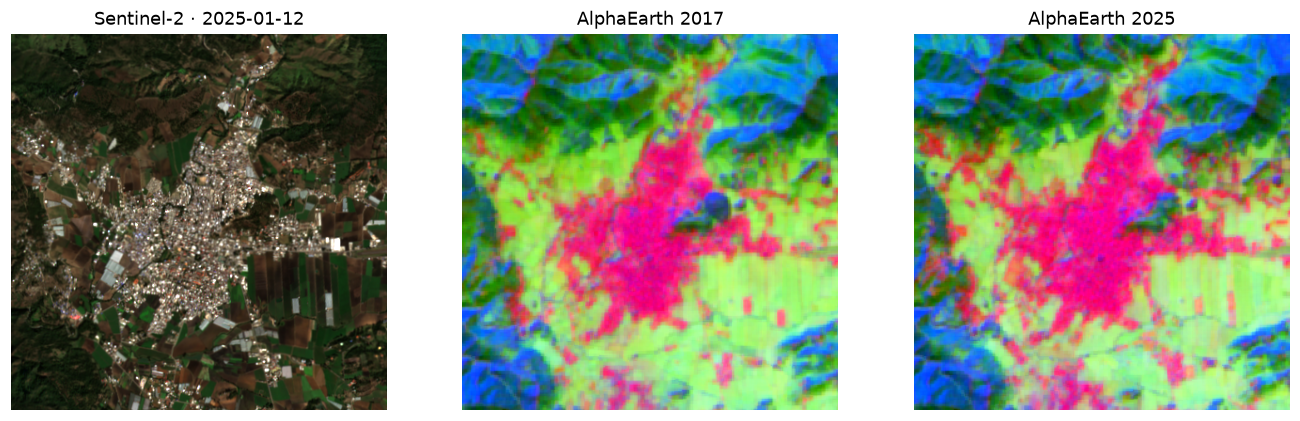

In [5]:
rgb_s2, s2_day = sentinel2_clearest(bbox, year_b)   # la foto real, para orientarse
rgb_a, rgb_b = embedding_rgb(A, B)                   # la MISMA escala de color para los dos años
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(rgb_s2); ax[0].set_title(f"Sentinel-2 · {s2_day}")
ax[1].imshow(rgb_a); ax[1].set_title(f"AlphaEarth {year_a}")
ax[2].imshow(rgb_b); ax[2].set_title(f"AlphaEarth {year_b}")
for a in ax: a.axis("off")
plt.show()

#### 📖 Cómo leer las imágenes
- La primera es una **foto real** de Sentinel-2 en la estación seca, para orientarte (el norte está arriba).
- En AlphaEarth, **colores parecidos = terrenos parecidos**. Los colores no tienen un significado fijo, pero los dos años usan **la misma escala**: donde el color cambió entre 2017 y 2025, cambió el terreno. El paso 2 lo mide con números.

#### 🔎 Qué vemos en el ejemplo (Constanza, 2017 → 2025)
- La foto muestra el pueblo en el centro del valle, rodeado de parcelas agrícolas rectangulares, y bosque en las montañas de los bordes.
- Con la misma escala, el pueblo sale en **rosa**, las parcelas en **verde claro** y el bosque de montaña en **azul y verde oscuro** en los dos años.
- Entre 2017 y 2025 la mancha rosa del pueblo **crece hacia el oeste y el suroeste** sobre parcelas que antes eran verde claro, y el bosque de las laderas casi no cambia.

In [6]:
analyze_figure(fig, f"{place}, República Dominicana. Izquierda: foto Sentinel-2 ({s2_day}). Centro y derecha: embeddings de "
                    f"AlphaEarth de {year_a} y {year_b} con la misma escala de color (colores iguales = terreno parecido; "
                    "los colores no tienen un significado fijo).")

   modelo ocupado, reintento 1…


   modelo ocupado, reintento 2…


   modelo ocupado, reintento 3…


**🤖 Análisis de Gemini**

Aquí tienes el análisis estructurado para gestión de riesgos de desastre, separando claramente lo que se observa de la interpretación:

### Lo que se VE (Datos directos de las imágenes)
* **Imagen óptica (izquierda):** Se observa un valle rodeado de laderas montañosas con vegetación boscosa, un río serpenteante y una zona urbana densa rodeada por campos agrícolas (muchos de ellos con invernaderos o cultivos estructurados).
* **Representaciones AlphaEarth (centro y derecha):** Las imágenes de 2017 y 2025 muestran mapas en color (donde tonos iguales indican propiedades de terreno similares). Al comparar 2017 con 2025, **no se aprecian diferencias cromáticas drásticas ni patrones anómalos evidentes** que sugieran un cambio masivo en el uso del suelo o una alteración catastrófica a gran escala en este periodo.

### Lo que se INTERPRETA (Análisis de riesgo)
* **Estabilidad relativa del territorio:** La aparente similitud entre los embeddings de 2017 y 2025 sugiere que la cobertura y los patrones superficiales en el valle y las laderas agrícolas de Constanza se han mantenido relativamente estables, sin eventos catastróficos visibles a esta resolución.
* **Limitaciones del método:** Con estos datos **no es posible determinar** la profundidad de los suelos, el estado real de conservación de las laderas, ni la vulnerabilidad específica ante eventos hidroclimáticos (como lluvias intensas o deslizamientos locales pequeños). Los embeddings de AlphaEarth muestran similitud espectral/estructural, pero no miden riesgo directo de desastre.

### Qué habría que verificar en terreno
* **Inspección física de laderas:** Es necesario realizar visitas de campo para evaluar la estabilidad real de los taludes y laderas agrícolas (pendientes pronunciadas con alta intervención agrícola), ya que procesos erosivos menores o deslizamientos superficiales locales pueden no ser visibles a la resolución de estas imágenes.
* **Control de prácticas agrícolas y drenajes:** Verificar en el terreno el manejo del agua, la deforestación local y el estado de los cauces de los ríos para complementar la evaluación de vulnerabilidad ante posibles inundaciones o remociones en masa en Constanza.

**🧠 Para pensar:** ¿reconoces el valle, el pueblo y las laderas en la foto de Sentinel-2?

## Paso 2 y 3 · ¿Dónde cambió, y en qué pendiente?

Comparamos la "huella" de cada píxel en los dos años: **0 = igual, cuanto más alto, más cambió**.
Después calculamos la **pendiente** con el modelo de elevación **Copernicus GLO-30**, que es abierto y está en AWS: la pendiente es cuánto sube el terreno por cada metro horizontal, expresado en grados.
Un cambio fuerte en un terreno empinado es una **señal**: ahí conviene mirar primero, porque es donde la erosión hace más daño.

In [7]:
def slope_degrees(bbox, shape):
    """Pendiente del terreno (grados) desde Copernicus DEM GLO-30, una cuadrícula de elevación de 30 m.
    Los archivos están organizados por cuadros de 1°×1°, nombrados por su esquina suroeste."""
    lat, lon = (bbox[1] + bbox[3]) / 2, (bbox[0] + bbox[2]) / 2
    ns, ew = ("N" if lat >= 0 else "S"), ("E" if lon >= 0 else "W")
    name = f"Copernicus_DSM_COG_10_{ns}{abs(math.floor(lat)):02d}_00_{ew}{abs(math.floor(lon)):03d}_00_DEM"
    url = f"/vsicurl/https://copernicus-dem-30m.s3.amazonaws.com/{name}/{name}.tif"
    elevation = resize_mask(read_window(url, bbox, shape[1])[0].astype("float32"), shape)
    pixel_m = math.sqrt(km2_per_pixel(bbox, shape)) * 1000
    dy, dx = np.gradient(elevation, pixel_m)            # metros que sube por metro recorrido
    return np.degrees(np.arctan(np.hypot(dx, dy)))


def erosion_signals(change, slope, change_min=0.15, slope_min=10.0):
    """Cambio fuerte EN terreno empinado: dónde conviene mirar primero (no es un diagnóstico)."""
    return (change > change_min) & (slope > slope_min)


def summary(bbox, change, slope, signals, labels=None, classes=None, change_min=0.15):
    """Los números clave del análisis, en km²."""
    px = km2_per_pixel(bbox, change.shape)
    out = {
        "area_km2": round(change.size * px, 1),
        "cambio_medio": round(float(np.nanmean(change)), 3),
        "km2_con_cambio_fuerte": round(float(np.nansum(change > change_min) * px), 2),
        "km2_en_pendiente_mayor_10": round(float(np.nansum(slope > 10) * px), 2),
        "km2_senal_erosion": round(float(signals.sum() * px), 2),
    }
    if labels is not None:
        out["que_hay_hoy_en_las_senales_km2"] = {
            str(k): round(float(((labels == k) & signals).sum() * px), 3) for k in classes}
    return out


def overlay(background, mask, color=(0.92, 0.26, 0.21)):
    """Fondo en grises y la máscara en rojo, engrosada 2 píxeles solo para que se vea."""
    from scipy.ndimage import binary_dilation
    bg = resize_mask(background, mask.shape) if background.shape[:2] != mask.shape else background
    gray = bg.mean(axis=2, keepdims=True)
    out = np.repeat(0.35 + 0.45 * gray, 3, axis=2)
    out[binary_dilation(mask, iterations=2)] = color
    return out

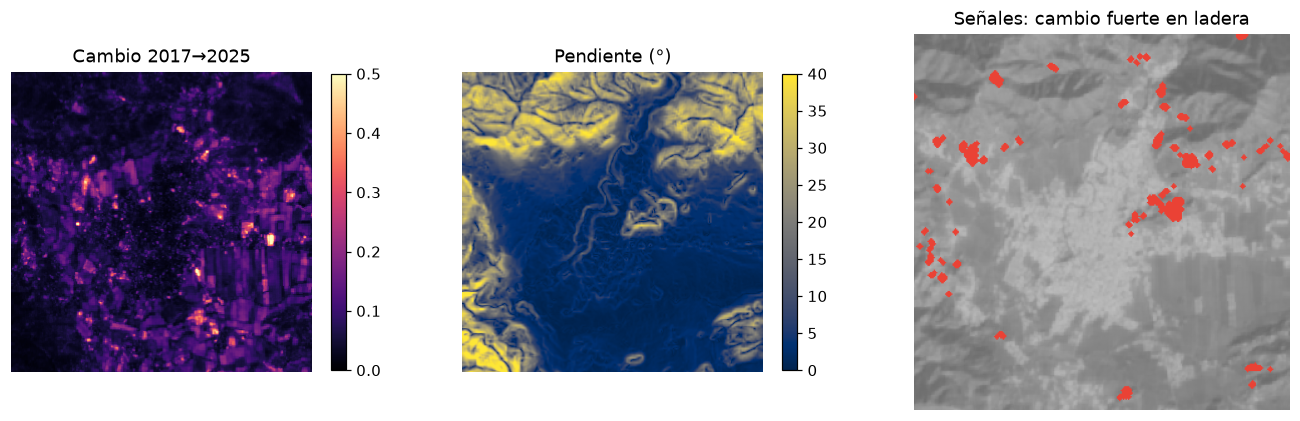

{'area_km2': 16.0,
 'cambio_medio': 0.073,
 'km2_con_cambio_fuerte': 1.21,
 'km2_en_pendiente_mayor_10': 6.24,
 'km2_senal_erosion': 0.12}

In [8]:
# @title Umbrales { run: "auto" }
CHANGE_MIN = 0.15     # @param {type:"slider", min:0.05, max:0.6, step:0.01}
SLOPE_MIN = 10        # @param {type:"slider", min:0, max:45, step:1}

change = change_between(A, B)
slope = slope_degrees(bbox, change.shape)
signals = erosion_signals(change, slope, CHANGE_MIN, SLOPE_MIN)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
im = ax[0].imshow(change, cmap="magma", vmin=0, vmax=0.5); ax[0].set_title(f"Cambio {year_a}→{year_b}"); plt.colorbar(im, ax=ax[0], shrink=0.7)
im = ax[1].imshow(slope, cmap="cividis", vmin=0, vmax=40); ax[1].set_title("Pendiente (°)"); plt.colorbar(im, ax=ax[1], shrink=0.7)
ax[2].imshow(overlay(embedding_rgb(B), signals)); ax[2].set_title("Señales: cambio fuerte en ladera")
for a in ax: a.axis("off")
plt.show()
summary(bbox, change, slope, signals, change_min=CHANGE_MIN)

#### 📖 Cómo leer los mapas y el resumen
- **Cambio**: negro = igual en los dos años; amarillo = cambió mucho. Con el umbral de 0,15 queda más o menos el 5 % de píxeles que más cambiaron.
- **Pendiente**: oscuro = plano; amarillo = empinado (40° es una ladera muy fuerte; 10° ya es suficiente para que la lluvia arrastre suelo desnudo).
- **Señales**: en rojo, los píxeles que cumplen **las dos** condiciones a la vez. Sobre fondo gris para que se vean.
- En el **resumen**: `km2_con_cambio_fuerte` es todo lo que cambió; `km2_senal_erosion` es solo lo que cambió **en ladera**. Si casi todo el cambio está en zona plana (como el valle de Constanza, con rotación de cultivos), la señal de erosión es pequeña.
- Mueve los umbrales: más bajos = más señales pero más "ruido"; más altos = menos señales y más seguras.

#### 🔎 Qué vemos en el ejemplo (Constanza, umbral 0,15 y pendiente 10°)
- De los **16 km²** analizados, **1,21 km²** (7,6 %) cambiaron fuerte entre 2017 y 2025, y **6,24 km²** (39 %) están en pendiente mayor de 10°.
- Pero solo **0,12 km²** cumplen las dos cosas: alrededor del **10 % del cambio fuerte está en ladera**. El resto ocurre en el valle plano, donde la rotación de cultivos cambia el suelo cada año sin riesgo de erosión.
- Esos 0,12 km² (unas 12 hectáreas) son la lista corta para revisar en terreno.

In [9]:
analyze_figure(fig, f"{place}, RD. Paneles: cambio de AlphaEarth {year_a}→{year_b} (0 = igual), pendiente en grados "
                    f"(Copernicus DEM) y, en rojo, señales = cambio > {CHANGE_MIN} en pendiente > {SLOPE_MIN}°. "
                    f"Resumen en km²: {summary(bbox, change, slope, signals, change_min=CHANGE_MIN)}")

   modelo ocupado, reintento 1…


   modelo ocupado, reintento 2…


   modelo ocupado, reintento 3…


**🤖 Análisis de Gemini**

Como analista de riesgo de desastres para Constanza (RD), aquí tienes la lectura técnica de los mapas y el resumen cuantitativo:

* **Lo que se VE (Datos directos):** 
  * El primer panel muestra la magnitud del cambio entre 2017 y 2025 según AlphaEarth (escala de 0 a 0.5), con un cambio medio de 0.073 en un área total de 16 km².
  * El segundo panel mapea la pendiente del terreno en grados (0° a 40°), donde 6.24 km² de la zona presentan pendientes superiores a 10°.
  * El tercer panel superpone en rojo las "señales" detectadas: puntos donde coinciden un cambio fuerte (> 0.15) y una pendiente mayor a 10°, abarcando una superficie de 0.12 km² (12 hectáreas).

* **Lo que se INTERPRETA (Análisis de riesgos):**
  * Los puntos rojos agrupados indican procesos activos de modificación del terreno (probablemente expansión agrícola, preparación de suelo o remociones) concentrados en zonas de ladera.
  * El patrón muestra que el cambio no ocurre de forma homogénea, sino focalizado en laderas específicas que superan el umbral de pendiente de 10°.

* **Conclusión prudente:** 
  * Existe un área delimitada (0.12 km²) donde la intervención antrópica o la dinámica del terreno en pendiente elevada amerita atención, ya que la combinación de ambos factores incrementa la vulnerabilidad a la erosión o deslizamientos ante eventos de lluvia intensa.

* **Lo que hay que verificar en terreno:**
  * Es necesario inspeccionar los sitios marcados en rojo para determinar la causa exacta del cambio (por ejemplo, si se trata de deforestación, preparación intensiva de cultivos, caminos rurales o deslizamientos reales).
  * No se puede saber con estos datos satelitales el impacto hidrológico exacto ni el nivel de daño a infraestructura sin una visita de campo y mediciones geotécnicas locales.

## Paso 4 · Clasificar con ejemplos (como *Classify* de Google Earth)

Le damos a la máquina **unos pocos ejemplos** de cada clase (fila y columna en la imagen) y un **Random Forest** aprende a reconocerlas usando los 64 números de AlphaEarth.
Un Random Forest es un conjunto de muchos árboles de decisión que votan. Es la técnica con la que se mapean **tipos de cultivo** a escala de país.
Los ejemplos de abajo son para Constanza. En la plataforma del paso 6 los marcas tú con clics.

In [10]:
CLASSES = {"Bosque": "#34a853", "Cultivo / pasto": "#f9ab00", "Suelo desnudo": "#ea4335",
           "Construido": "#9e9e9e", "Agua": "#4285f4"}

# Ejemplos para Constanza: (fila, columna, clase) en la imagen de 300×300 píxeles.
# La fila 0 es el borde norte y la columna 0 el borde oeste.
EXAMPLES_CONSTANZA = (
    [(20, 40, "Bosque"), (40, 250, "Bosque"), (275, 30, "Bosque"), (60, 15, "Bosque"), (15, 280, "Bosque")]
    + [(150, 150, "Construido"), (185, 140, "Construido"), (120, 170, "Construido"), (205, 115, "Construido")]
    + [(195, 215, "Cultivo / pasto"), (105, 215, "Cultivo / pasto"), (240, 282, "Cultivo / pasto"), (135, 258, "Cultivo / pasto")]
    + [(218, 268, "Suelo desnudo"), (268, 168, "Suelo desnudo"), (130, 95, "Suelo desnudo"), (262, 232, "Suelo desnudo")]
)


def classify(emb, examples):
    """Entrena un Random Forest con los ejemplos y clasifica todos los píxeles.
    Por cada ejemplo toma también sus 8 vecinos (3×3 píxeles) para tener más datos."""
    from sklearn.ensemble import RandomForestClassifier
    c, h, w = emb.shape
    X, y = [], []
    for row, col, label in examples:
        for dr in (-1, 0, 1):
            for dc in (-1, 0, 1):
                r, k = min(max(row + dr, 0), h - 1), min(max(col + dc, 0), w - 1)
                v = emb[:, r, k]
                if not np.isnan(v).any():
                    X.append(v); y.append(label)
    if len(set(y)) < 2:
        raise ValueError("Marca ejemplos de al menos dos clases.")
    forest = RandomForestClassifier(n_estimators=120, random_state=0, n_jobs=-1).fit(X, y)
    labels = forest.predict(np.nan_to_num(emb.reshape(c, -1).T)).reshape(h, w)
    return labels, list(forest.classes_)


def colorize(labels, classes):
    """Pinta cada clase con su color."""
    from matplotlib.colors import to_rgb
    out = np.zeros(labels.shape + (3,))
    for k in classes:
        out[labels == k] = to_rgb(CLASSES.get(k, "#000000"))
    return out

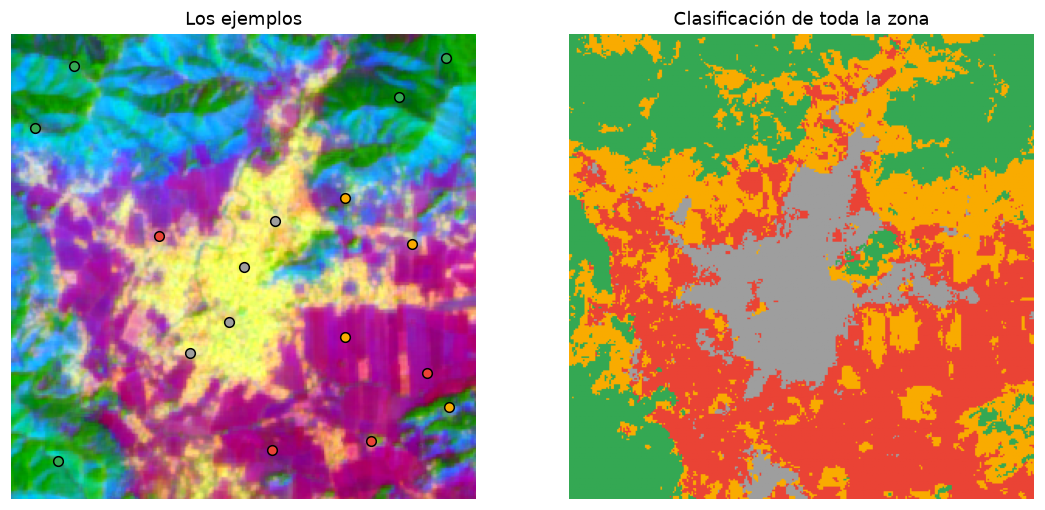

{'area_km2': 16.0,
 'cambio_medio': 0.073,
 'km2_con_cambio_fuerte': 1.21,
 'km2_en_pendiente_mayor_10': 6.24,
 'km2_senal_erosion': 0.12,
 'que_hay_hoy_en_las_senales_km2': {'Bosque': 0.021,
  'Construido': 0.006,
  'Cultivo / pasto': 0.076,
  'Suelo desnudo': 0.021}}

In [11]:
EXAMPLES = EXAMPLES_CONSTANZA if place.startswith("Constanza") else []
labels, classes = (None, None)
if EXAMPLES:
    labels, classes = classify(B, EXAMPLES)
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(embedding_rgb(B))
    for row, col, label in EXAMPLES:
        ax[0].scatter(col, row, s=40, color=CLASSES[label], edgecolor="black")
    ax[0].set_title("Los ejemplos")
    ax[1].imshow(colorize(labels, classes)); ax[1].set_title("Clasificación de toda la zona")
    for a in ax: a.axis("off")
    plt.show()
    display(summary(bbox, change, slope, signals, labels, classes, CHANGE_MIN))
else:
    print("Para otros lugares, marca tus ejemplos en la plataforma del paso 6.")

#### 📖 Cómo leer la clasificación
- Cada color es una clase: **verde** bosque, **amarillo** cultivo o pasto, **rojo** suelo desnudo, **gris** construido, **azul** agua.
- Compárala con la foto de Sentinel-2 del paso 1: donde no coincida, el modelo se equivocó o le faltan ejemplos de esa zona.
- En el resumen, `que_hay_hoy_en_las_senales_km2` dice **qué hay hoy** en los píxeles con señal de erosión. Si la mayoría es *Suelo desnudo* en ladera, es lo primero que habría que revisar en terreno.

#### 🔎 Qué vemos en el ejemplo
- En las 0,12 km² con señal hoy hay sobre todo **cultivo o pasto (0,076 km², unas dos terceras partes)**, y menos **bosque (0,021)**, **suelo desnudo (0,021)** y **construido (0,006)**.
- Lectura: la mayoría de las señales son **parcelas agrícolas en ladera**. Eso no es erosión por sí mismo, pero es donde el suelo queda expuesto entre cosechas.
- Lo primero que verificaría en terreno: las **2 hectáreas de suelo desnudo en pendiente**.

In [12]:
if EXAMPLES:
    analyze_figure(fig, f"{place}, RD. Izquierda: ejemplos marcados sobre AlphaEarth {year_b}. Derecha: clasificación con "
                        "Random Forest (verde bosque, amarillo cultivo/pasto, rojo suelo desnudo, gris construido, azul agua). "
                        f"Qué hay hoy en las señales de erosión (km²): {summary(bbox, change, slope, signals, labels, classes, CHANGE_MIN)}")

   modelo ocupado, reintento 1…


   modelo ocupado, reintento 2…


   modelo ocupado, reintento 3…


**🤖 Análisis de Gemini**

Aquí tienes el análisis estructurado para gestión de riesgos, separando claramente lo observable de lo interpretado:

*   **Lo que se VE (izquierda):** Una imagen satelital de Constanza con puntos de colores que sirven como ejemplos de entrenamiento para un modelo informático (*Random Forest*).
*   **Lo que se VE (derecha):** Un mapa clasificado por colores que divide la zona en cuatro categorías: verde (bosque), amarillo (cultivo/pasto), rojo (suelo desnudo) y gris (construido). No se observan cuerpos de agua marcados en azul.
*   **Lo que se INTERPRETA:** El modelo clasifica el centro de la zona principalmente como área construida (gris), rodeada por una extensa matriz de cultivos/pastos (amarillo) y suelo desnudo (rojo), con parches de bosque (verde) confinados principalmente a las partes altas y montañosas.
*   **Lo que se INTERPRETA (riesgo):** Según los datos numéricos anexos, hay 6.24 km² en pendientes mayores a 10 grados y 0.12 km² con señal de erosión actual (distribuida en 0.076 km² de cultivo/pasto, 0.021 km² de suelo desnudo y 0.021 km² de bosque). Esto indica vulnerabilidad en laderas agrícolas.
*   **Qué habría que verificar en terreno:** Es necesario comprobar el estado real de los cultivos en pendiente, la efectividad de las prácticas de conservación de suelos y si las zonas marcadas como "suelo desnudo" o "cultivo/pasto" presentan surcos activos de erosión o deslizamientos incipientes.
*   **Limitaciones (lo que no se sabe):** Con estos datos satelitales y de clasificación automática no se puede conocer el nivel exacto de pérdida económica ni el grado de amenaza directa a infraestructuras específicas sin una inspección física detallada.

## Paso 5 · El informe
Gemini convierte los números en un párrafo para alguien que no es técnico, sin inventar causas.

In [13]:
REPORT_INSTRUCTIONS = (
    "Eres analista de riesgo ambiental en República Dominicana. Con estos números de un análisis satelital "
    "automático (AlphaEarth + pendiente Copernicus), escribe 5 líneas en español sencillo: qué cambió, dónde "
    "mirar primero y qué verificar en terreno. No inventes causas ni nombres; es una señal, no un diagnóstico.\n")

data = summary(bbox, change, slope, signals, labels, classes, CHANGE_MIN)
data["lugar"] = place
data["años"] = f"{year_a}→{year_b}"
print(generate(client, model, REPORT_INSTRUCTIONS + json.dumps(data, ensure_ascii=False)).text)

   modelo ocupado, reintento 1…


   modelo ocupado, reintento 2…


   modelo ocupado, reintento 3…


Entre 2017 y 2025, el análisis detectó una alteración moderada en 1.21 km² de laderas agrícolas en Constanza.
El cambio se concentra principalmente en zonas con pendientes mayores a 10 grados, donde hay 6.24 km² expuestos.
Debemos mirar primero las áreas de cultivo y pasto, que suman 0.076 km² con señales de cambio.
En terreno es necesario verificar el estado real de los 0.12 km² marcados con señal directa de erosión.
También hay que revisar los 0.021 km² de suelo desnudo y los 0.021 km² de bosque afectados para descartar degradación.


**📖 Cómo leer el informe:** compara cada cifra del texto con el resumen de arriba. Si el informe menciona algo que no está en los números (una causa, un nombre de finca, una fecha), es una invención del modelo y hay que borrarlo.

## Paso 6 · 🚀 Tu plataforma

La siguiente celda junta todo en una **app web** con Gradio. Al ejecutarla aparece la app debajo de la celda y un enlace `*.gradio.live` que puedes **compartir con quien quieras** durante 72 horas.
1. Elige un lugar (o *Mis coordenadas* y escribe latitud y longitud) y pulsa **1 · Cargar el lugar**. Los lugares sin copia tardan unos 2 minutos.
2. Elige una clase y **haz clic en la imagen de AlphaEarth** para marcar ejemplos (al menos 3 por clase, de 2 clases o más).
3. Pulsa **2 · Clasificar y recalcular** y mueve los umbrales.
4. Pide el **informe** a Gemini.

In [14]:
def launch_app(share=True):
    """Crea la app web: los mismos pasos del cuaderno, con botones."""
    import gradio as gr
    state = {}   # aquí se guarda lo calculado entre un clic y otro

    def load(place_name, lat, lon, ya, yb):
        if place_name in PLACES_RD:
            lat, lon = PLACES_RD[place_name]
        box = bbox_around(lat, lon, 4)
        years = (int(ya), int(yb))
        s = alphaearth_series(box, years, saved_copy=SAVED_COPIES.get(place_name))
        a, b = s[years[0]], s[years[1]]
        ch = change_between(a, b)
        sl = slope_degrees(box, ch.shape)
        rgb_b = embedding_rgb(b)
        state.update(bbox=box, b=b, change=ch, slope=sl, rgb_b=rgb_b, examples=[], place=place_name)
        sig = erosion_signals(ch, sl)
        return (rgb_b, np.clip(ch / 0.5, 0, 1), np.clip(sl / 40, 0, 1), overlay(rgb_b, sig),
                summary(box, ch, sl, sig), "Haz clic en la imagen de AlphaEarth para marcar ejemplos.")

    def mark(label, evt: gr.SelectData):
        col, row = evt.index                       # Gradio da (x, y) = (columna, fila)
        state.setdefault("examples", []).append((int(row), int(col), label))
        counts = {k: sum(1 for e in state["examples"] if e[2] == k) for k in CLASSES}
        return ", ".join(f"{k}: {v}" for k, v in counts.items() if v)

    def classify_ui(change_min, slope_min):
        lab, cls = classify(state["b"], state["examples"])
        sig = erosion_signals(state["change"], state["slope"], change_min, slope_min)
        state.update(labels=lab, classes=cls, signals=sig)
        return (colorize(lab, cls), overlay(state["rgb_b"], sig),
                summary(state["bbox"], state["change"], state["slope"], sig, lab, cls, change_min))

    def report():
        cli = gemini_client()
        sig = state.get("signals", erosion_signals(state["change"], state["slope"]))
        d = summary(state["bbox"], state["change"], state["slope"], sig, state.get("labels"), state.get("classes"))
        d["lugar"] = state.get("place")
        return generate(cli, pick_model(cli, "flash"), REPORT_INSTRUCTIONS + json.dumps(d, ensure_ascii=False)).text

    with gr.Blocks(title="Vigilancia satelital · DevFest SDQ") as demo:
        gr.Markdown("## 🛰️ Mi plataforma de vigilancia satelital\nAlphaEarth Foundations + pendiente del terreno · "
                    "señales para revisar, no diagnósticos.")
        with gr.Row():
            place_in = gr.Dropdown(list(PLACES_RD) + ["Mis coordenadas"], value=list(PLACES_RD)[0], label="Lugar")
            lat_in = gr.Number(18.4861, label="Latitud (si eliges «Mis coordenadas»)")
            lon_in = gr.Number(-69.9312, label="Longitud")
            ya_in = gr.Dropdown([str(y) for y in range(2017, 2026)], value="2017", label="Año A")
            yb_in = gr.Dropdown([str(y) for y in range(2017, 2026)], value="2025", label="Año B")
        load_btn = gr.Button("1 · Cargar el lugar", variant="primary")
        with gr.Row():
            img_emb = gr.Image(label="AlphaEarth (año B) · haz clic para marcar ejemplos", interactive=False)
            img_change = gr.Image(label="Cambio A→B (claro = mucho)")
            img_slope = gr.Image(label="Pendiente (claro = empinado)")
            img_signals = gr.Image(label="Señales: cambio fuerte en ladera")
        with gr.Row():
            class_in = gr.Radio(list(CLASSES), value="Bosque", label="Clase del próximo clic")
            counts_out = gr.Textbox(label="Ejemplos marcados (mínimo 3 por clase)")
        with gr.Row():
            change_in = gr.Slider(0.05, 0.6, 0.15, step=0.01, label="Umbral de cambio")
            slope_in = gr.Slider(0, 45, 10, step=1, label="Pendiente mínima (°)")
            classify_btn = gr.Button("2 · Clasificar y recalcular", variant="primary")
        with gr.Row():
            img_classes = gr.Image(label="Qué hay hoy (clasificación)")
            img_signals2 = gr.Image(label="Señales con tus umbrales")
            table = gr.JSON(label="Resumen")
        report_btn = gr.Button("3 · Informe con Gemini")
        report_out = gr.Markdown()
        load_btn.click(load, [place_in, lat_in, lon_in, ya_in, yb_in],
                       [img_emb, img_change, img_slope, img_signals, table, counts_out])
        img_emb.select(mark, [class_in], counts_out)
        classify_btn.click(classify_ui, [change_in, slope_in], [img_classes, img_signals2, table])
        report_btn.click(report, None, report_out)
    demo.launch(share=share, debug=False)
    return demo


launch_app()

(En la versión ejecutada la app no se lanza: ejecuta esta celda en Colab para abrirla.)


## Paso 7 · 🔧 Adapta el cuaderno a otro lugar

- **Otro lugar de la lista:** cambia `place` en la celda *El lugar*. Fuera de Constanza, AlphaEarth se lee en vivo (alrededor de 1 minuto por año).
- **Tu propio lugar:** añade una línea a `PLACES_RD`, por ejemplo `"Jarabacoa": (19.118, -70.637),`, ejecuta esa celda y añade el mismo nombre a la lista entre corchetes de `# @param` en *El lugar*. Las coordenadas salen de Google Maps (clic derecho sobre el mapa). Funciona en cualquier país: AlphaEarth cubre toda la tierra firme.
- **Otros años:** cambia `year_a, year_b` (de 2017 a 2025). Comparar años seguidos (2024→2025) muestra cambios recientes; años lejanos (2017→2025), la tendencia.
- **Otra escala:** cambia `KM`. Más grande = más área pero más lento y con píxeles más gruesos (el ancho se mantiene en 300 píxeles).
- **Tus propios ejemplos:** en la plataforma, con clics; o en código, una lista `(fila, columna, clase)` como `EXAMPLES_CONSTANZA`. Para saber la fila y la columna de un punto, dibuja la imagen con `plt.imshow(embedding_rgb(B)); plt.grid(True)` y lee los ejes.
- **Otra pregunta:** cambia `erosion_signals`. Por ejemplo, para expansión urbana: píxeles con cambio fuerte que **hoy** son *Construido*: `(change > CHANGE_MIN) & (labels == "Construido")`.

## 🏁 Retos
1. Cambia el año A a **2020** en la plataforma. ¿Las señales se concentran en los mismos sitios?
2. En **Cotuí** o en el **río Nizao**, marca ejemplos de *Suelo desnudo* y *Agua*. ¿Qué parte de las señales es suelo expuesto hoy?
3. Busca tu provincia con *Mis coordenadas* y comparte el enlace de tu plataforma en el chat del GDG.

## 🆘 Si algo falla

| Lo que ves | Qué hacer |
|---|---|
| `NameError: name '...' is not defined` | Te saltaste una celda: cada paso usa funciones definidas antes. Usa **Runtime → Run before** (*Entorno de ejecución → Ejecutar anteriores*). |
| `ModuleNotFoundError` | Ejecuta otra vez la primera celda (la que instala librerías). |
| `No encuentro tu key` o `Falta GOOGLE_API_KEY` | Revisa el bloque 🔑: el nombre debe ser exactamente `GOOGLE_API_KEY` y *Notebook access* debe estar activo. |
| `429` o `RESOURCE_EXHAUSTED` | Llegaste al límite gratuito por minuto. Espera un minuto y vuelve a ejecutar la celda. |
| `503` o `UNAVAILABLE` | El modelo está saturado. El código reintenta solo; si aun así falla, prueba de nuevo en un minuto. |
| `HTTP Error 404` al descargar | La dirección no existe: revisa la fecha o el identificador que escribiste. |
| Una celda tarda mucho | Las celdas con `LIVE = True` leen datos en directo y dependen de la red. Ponlas en `False` para usar la copia guardada en GitHub. |
| Todo se rompió | **Runtime → Restart session** y ejecuta de nuevo desde la primera celda. |
| La app no abre o el enlace `gradio.live` no carga | Usa la vista que aparece debajo de la celda, dentro del propio Colab. El enlace público a veces tarda unos segundos. |
| Quiero volver a lanzar la app | Detén la celda con ⏹️ y ejecútala otra vez. |

---
**Fuentes y licencias.** AlphaEarth Foundations Satellite Embedding: Google DeepMind / Earth Engine, copia en Source Cooperative (CC BY 4.0).
Copernicus DEM GLO-30 (© DLR/Airbus, licencia Copernicus, vía AWS Open Data). Sentinel-2 L2A: Copernicus (ESA/UE) vía Earth Search.
Inspiración: Amazon Mining Watch (Earth Genome y aliados) y Google Earth *Classify*. Los resultados son señales para verificar en terreno, no diagnósticos.